# AHCD: understanding and checking the images

This notebook checks the shared training data before comparing CNN experiments. It displays results directly and does not change any dataset files or splits. The original test images are not opened.

Run from `04_neural-networks/` using NumPy, pandas and Matplotlib. The code uses built-in library functions without custom helper functions. This is a retrospective audit completed after the first model runs.

## 1. Load the images and check the files

Check image sizes, missing values, pixel values and labels. Compare the prepared images with the original training CSVs to confirm preparation preserved the data.

In [1]:
from pathlib import Path
from zipfile import ZipFile
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Load files using a path relative to this notebook folder.
shared_folder = Path("../data/ahcd/shared")

# Load compressed images and labels. Pixel values are still 0 to 255.

with np.load(shared_folder / "training_data.npz", allow_pickle=False) as data:
    images = data["images"]
    labels = data["labels"]

# Load saved row positions so every model uses the same split.

with np.load(shared_folder / "split_indices.npz", allow_pickle=False) as data:
    train_indices = data["train_indices"]
    validation_indices = data["validation_indices"]

# Read the dataset source and preparation notes.
info = json.loads((shared_folder / "data_info.json").read_text())
print("Source:", info["source"])
print("Authors:", info["authors_repository"])
print("Images:", images.shape, images.dtype)
print("Labels:", labels.shape, labels.dtype)

with ZipFile("../data/ahcd/AHCD.zip") as archive:
    with archive.open("csvTrainImages 13440x1024.csv") as file:

        # The CSV has no column header, so keep the first row as data.
        raw_pixels = pd.read_csv(file, header=None)

    with archive.open("csvTrainLabel 13440x1.csv") as file:

        # Convert the single label column to a one-dimensional Series.
        raw_labels = pd.read_csv(file, header=None).squeeze("columns")

print("Original training table:")
raw_pixels.info()

# Recreate the documented CSV reshape and orientation correction for comparison only.
expected_images = raw_pixels.to_numpy().reshape(-1, 32, 32).transpose(0, 2, 1)

# Give each input check a name and show whether it passed.
checks = pd.Series({
    "expected image shape": images.shape == (13440, 1, 32, 32),
    "no missing original pixels": not raw_pixels.isna().any().any(),
    "no missing original labels": not raw_labels.isna().any(),
    "finite prepared pixels": np.isfinite(images).all(),
    "pixel range valid": bool((images.min() >= 0) and (images.max() <= 255)),
    "original pixels are integers": bool(np.equal(raw_pixels, np.floor(raw_pixels)).all().all()),
    "prepared images match original conversion": np.array_equal(images[:, 0], expected_images),
    "prepared labels match original labels minus one": np.array_equal(labels, raw_labels.to_numpy() - 1),
    "all 28 class labels present": np.array_equal(np.unique(labels), np.arange(28)),
}, name="passed")

display(checks.to_frame())

# Stop if an input check fails before continuing the analysis.

assert checks.all(), "Review a failed input check before interpreting subsequent analysis."

print("Observations:")
print("- All structure and source-to-prepared checks passed.")
print("- Preparation preserves the original training rows and documented labels.")
print("Summary: missing-value imputation is not needed for these supplied inputs.")
print("Next: examine whether class frequencies and split membership are consistent.")

Source: https://www.kaggle.com/datasets/mloey1/ahcd1
Authors: https://github.com/mloey/Arabic-Handwritten-Characters-Dataset
Images: (13440, 1, 32, 32) uint8
Labels: (13440,) int64
Original training table:
<class 'pandas.DataFrame'>
RangeIndex: 13440 entries, 0 to 13439
Columns: 1024 entries, 0 to 1023
dtypes: int64(1024)
memory usage: 105.0 MB
Observations:
- All structure and source-to-prepared checks passed.
- Preparation preserves the original training rows and documented labels.
Summary: missing-value imputation is not needed for these supplied inputs.
Next: examine whether class frequencies and split membership are consistent.


,passed
expected image shape,True
no missing original pixels,True
no missing original labels,True
finite prepared pixels,True
pixel range valid,True
original pixels are integers,True
prepared images match original conversion,True
prepared labels match original labels minus one,True
all 28 class labels present,True


## 2. Check class counts and the split

Check that fitting and validation contain different row indices and that every row is included once. Count examples per class to see whether balancing is needed.

Observations:
- 10,752 fitting images and 2,688 validation images.
- Per-class fitting counts range from 384 to 384.
- Per-class validation counts range from 96 to 96.
Summary: this balanced split does not motivate class weighting solely from frequency.
Next: visually examine several examples per class rather than assuming labels are correct.


,passed
training indices unique,True
validation indices unique,True
no shared row indices,True
all rows covered,True


,all_training_portion,fitting,validation,validation_fraction
internal_class,,,,
0,480,384,96,0.2
1,480,384,96,0.2
2,480,384,96,0.2
3,480,384,96,0.2
4,480,384,96,0.2
5,480,384,96,0.2
6,480,384,96,0.2
7,480,384,96,0.2
8,480,384,96,0.2


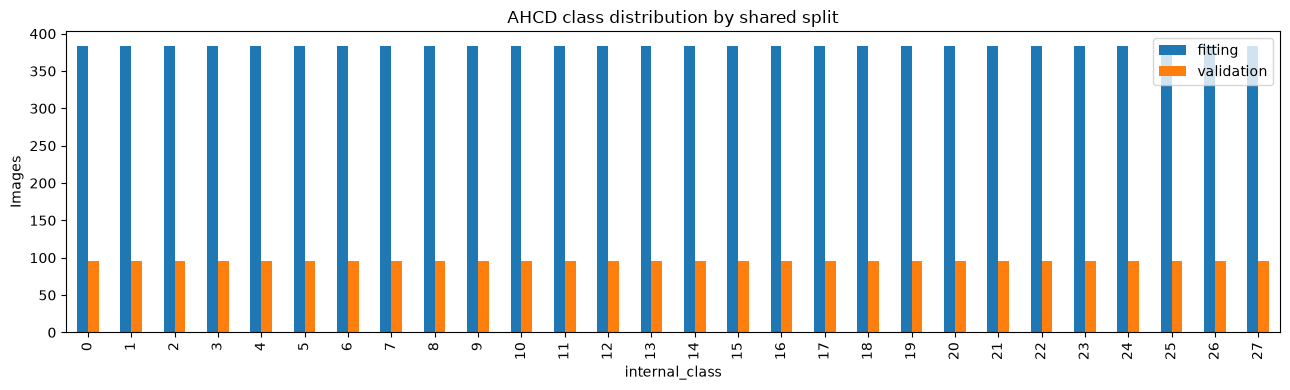

In [2]:
# Check unique rows, no row overlap and complete coverage of the shared inputs.
split_checks = pd.Series({
    "training indices unique": len(np.unique(train_indices)) == len(train_indices),
    "validation indices unique": len(np.unique(validation_indices)) == len(validation_indices),
    "no shared row indices": np.intersect1d(train_indices, validation_indices).size == 0,
    "all rows covered": np.array_equal(
        np.sort(np.concatenate([train_indices, validation_indices])), np.arange(len(labels))
    ),
}, name="passed")

display(split_checks.to_frame())

assert split_checks.all()

# Count images for each class in the full data and both subsets.
counts = pd.DataFrame({
    "all_training_portion": pd.Series(labels).value_counts(),
    "fitting": pd.Series(labels[train_indices]).value_counts(),
    "validation": pd.Series(labels[validation_indices]).value_counts(),
}).sort_index()
counts.index.name = "internal_class"

# Calculate the fraction of each class assigned to validation.
counts["validation_fraction"] = counts["validation"] / counts["all_training_portion"]

display(counts)
counts[["fitting", "validation"]].plot.bar(figsize=(13, 4), ylabel="Images")
plt.title("AHCD class distribution by shared split")

plt.tight_layout()

plt.show()

print("Observations:")
print(f"- {len(train_indices):,} fitting images and {len(validation_indices):,} validation images.")
print(f"- Per-class fitting counts range from {counts.fitting.min()} to {counts.fitting.max()}.")
print(f"- Per-class validation counts range from {counts.validation.min()} to {counts.validation.max()}.")
print("Summary: this balanced split does not motivate class weighting solely from frequency.")
print("Next: visually examine several examples per class rather than assuming labels are correct.")

## 3. Look at example characters

Show three fitting images per class using a fixed random seed. Look for orientation, handwriting variation and obvious problems. This small sample does not verify every label.

Observations:
- The grid shows three fitting examples for each of the 28 classes.
- Bright strokes and dark background can be checked against the intensity summaries below.
Summary: inspect character orientation and label plausibility visually before making a quality claim.
Next: quantify intensity and ink coverage. A varied appearance alone is not a reason to delete an image.


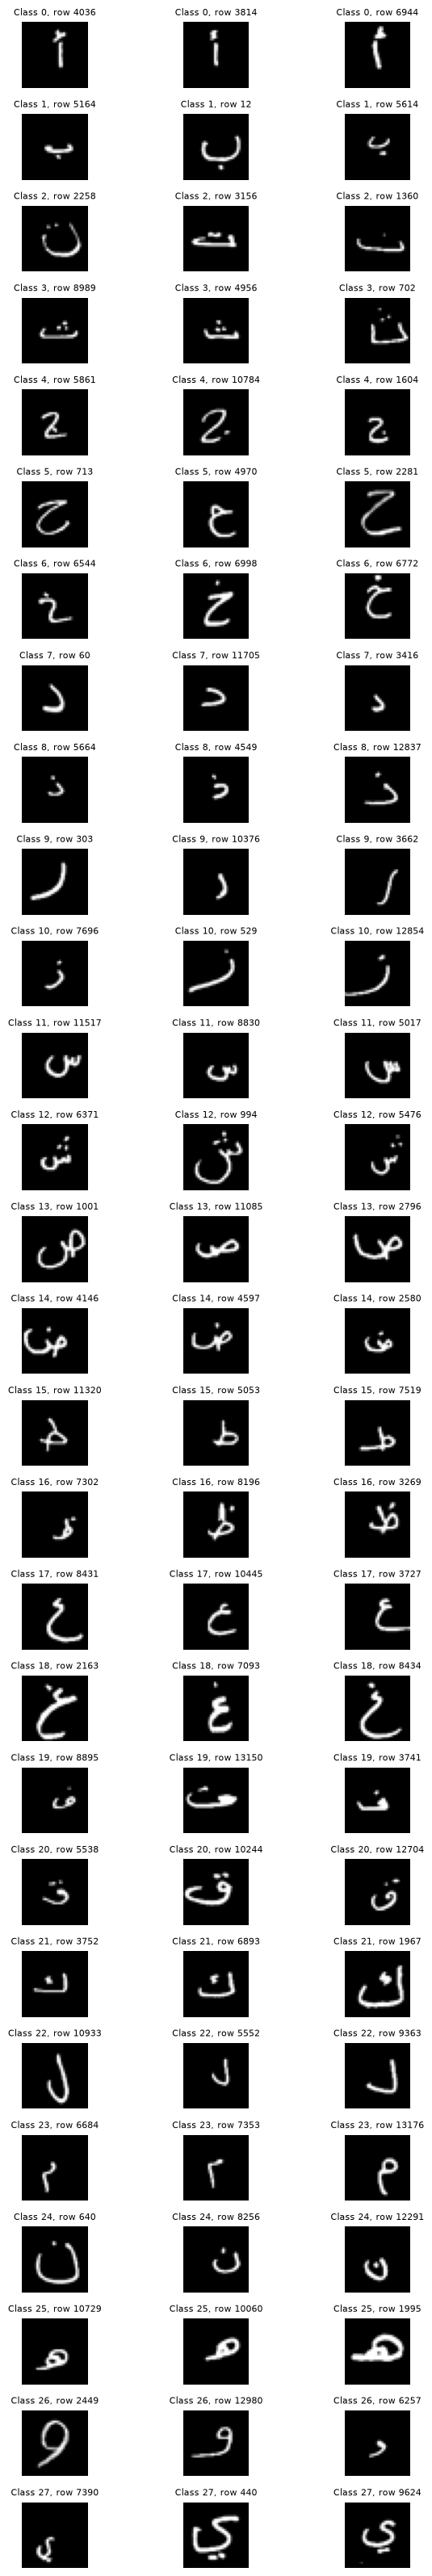

In [3]:
# Use a fixed seed so these example images are repeatable.
rng = np.random.default_rng(42)

fig, axes = plt.subplots(28, 3, figsize=(7, 32))

for class_id in range(28):

    # Select fitting rows belonging to this class.
    candidates = train_indices[labels[train_indices] == class_id]

    # Choose three different examples without repeating rows.
    selected = rng.choice(candidates, size=3, replace=False)

    for column, row in enumerate(selected):

        # Show the image with the same brightness scale in every panel.
        axes[class_id, column].imshow(images[row, 0], cmap="gray", vmin=0, vmax=255)
        axes[class_id, column].set_title(f"Class {class_id}, row {row}", fontsize=8)
        axes[class_id, column].axis("off")

fig.tight_layout()

plt.show()

print("Observations:")
print("- The grid shows three fitting examples for each of the 28 classes.")
print("- Bright strokes and dark background can be checked against the intensity summaries below.")
print("Summary: inspect character orientation and label plausibility visually before making a quality claim.")
print("Next: quantify intensity and ink coverage. A varied appearance alone is not a reason to delete an image.")

## 4. Look at brightness and ink coverage

Summarize fitting images only. Ink coverage here means the fraction of pixels greater than zero, including faint strokes. It helps describe images but is not a quality score.

Observations:
- Zero-valued pixels comprise 89.9% of fitting pixels.
- Median fitting foreground fraction is 9.7%.
Summary: dividing by the known maximum 255 gives a fixed 0 to 1 scale without learning from validation.
Next: inspect extreme images directly before considering preprocessing changes.


,count,mean,std,min,25%,50%,75%,max
mean_intensity,10752.0,13.452327,5.824485,0.0,9.388916,12.669434,16.473633,42.542969
intensity_std,10752.0,48.138422,10.436656,0.0,41.041638,47.825093,54.585040,87.925465
foreground_fraction,10752.0,0.100781,0.037406,0.0,0.074219,0.096680,0.122070,0.261719
maximum_intensity,10752.0,254.843936,2.893292,0.0,255.000000,255.000000,255.000000,255.000000
minimum_intensity,10752.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000


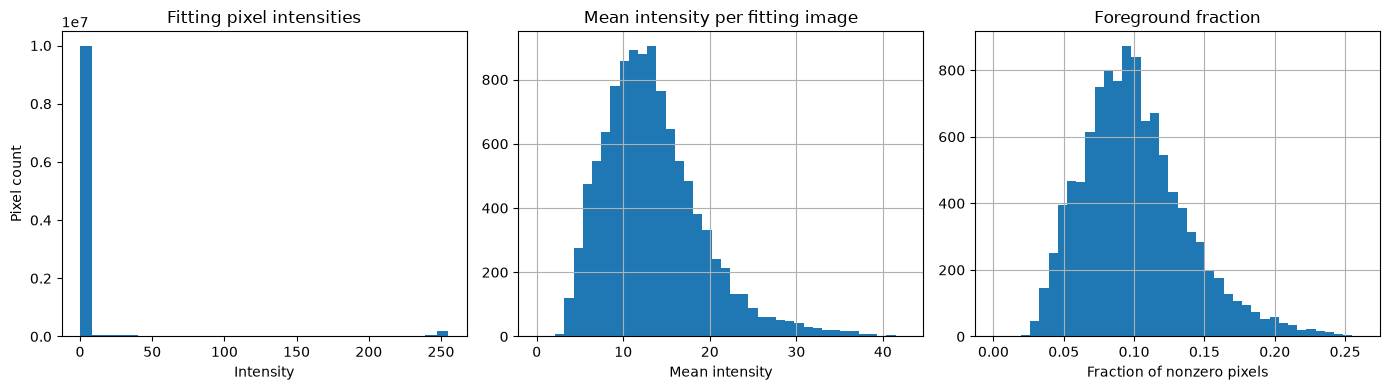

In [4]:
# Remove the single channel dimension for plotting and summaries.
pixels = images[:, 0]

# Use one row per image and one column per pixel for these checks.
flat = pixels.reshape(len(images), -1)

# Summarize each image. axis=1 means calculate across its pixels.
image_stats = pd.DataFrame({
    "class": labels,
    "mean_intensity": flat.mean(axis=1),
    "intensity_std": flat.std(axis=1),
    "foreground_fraction": (flat > 0).mean(axis=1),
    "maximum_intensity": flat.max(axis=1),
    "minimum_intensity": flat.min(axis=1),
})

# Use fitting rows for summaries that may guide preprocessing.
fit_stats = image_stats.iloc[train_indices]

# Summarize numerical image properties, excluding categorical class IDs.

display(fit_stats.drop(columns="class").describe().T)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Combine fitting pixels into one vector to plot their intensity distribution.
axes[0].hist(pixels[train_indices].ravel(), bins=32)
axes[0].set(title="Fitting pixel intensities", xlabel="Intensity", ylabel="Pixel count")
fit_stats["mean_intensity"].hist(bins=40, ax=axes[1])
axes[1].set(title="Mean intensity per fitting image", xlabel="Mean intensity")
fit_stats["foreground_fraction"].hist(bins=40, ax=axes[2])
axes[2].set(title="Foreground fraction", xlabel="Fraction of nonzero pixels")
fig.tight_layout()

plt.show()

print("Observations:")
print(f"- Zero-valued pixels comprise {(pixels[train_indices] == 0).mean():.1%} of fitting pixels.")
print(f"- Median fitting foreground fraction is {fit_stats.foreground_fraction.median():.1%}.")
print("Summary: dividing by the known maximum 255 gives a fixed 0 to 1 scale without learning from validation.")
print("Next: inspect extreme images directly before considering preprocessing changes.")

## 5. Find blank images and inspect extremes

An all-zero image is blank. An image with the same value everywhere is constant. Inspect images with low and high coverage before deciding whether they are problematic.

Observations:
- All-zero images across the shared training portion: 1.
- Constant-intensity images across the shared training portion: 1.
Summary: the displayed extremes are candidates for visual inspection, not automatically invalid samples.
Next: check exact duplicate image content and cross-split overlap.


,fitting,validation
all_zero,1,0
constant_intensity,1,0


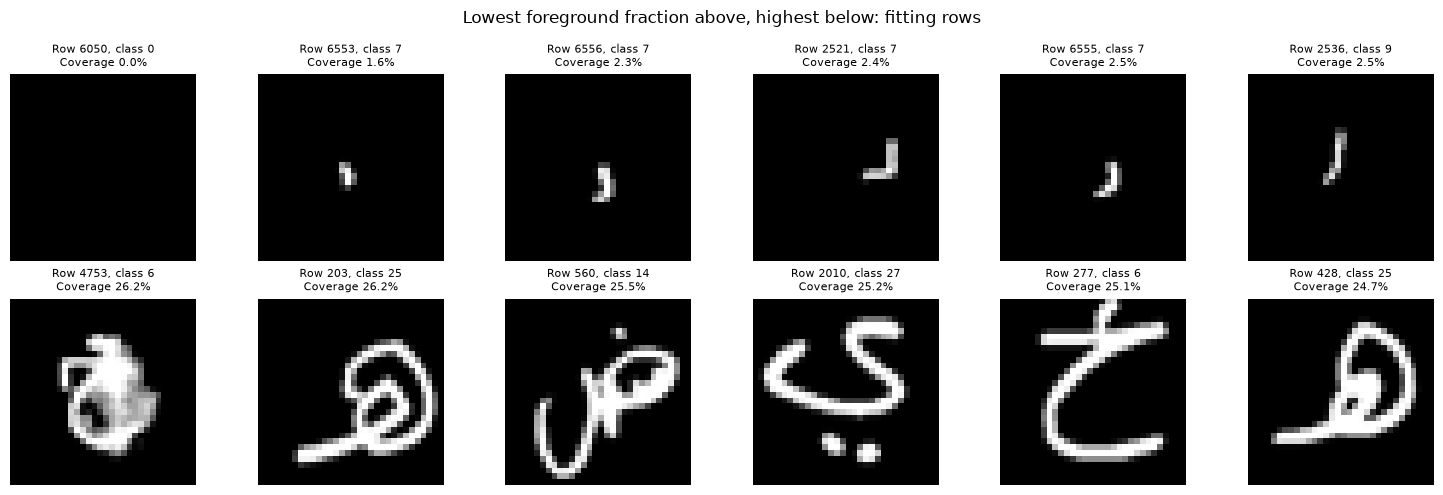

In [5]:
# Equal minimum and maximum means every pixel in that image is the same.
constant = flat.max(axis=1) == flat.min(axis=1)

# With nonnegative pixels, a maximum of zero means the image is entirely blank.
blank = flat.max(axis=1) == 0

# Count flagged images separately in fitting and validation without removing them.
quality_counts = pd.DataFrame({
    "fitting": [int(blank[train_indices].sum()), int(constant[train_indices].sum())],
    "validation": [int(blank[validation_indices].sum()), int(constant[validation_indices].sum())],
}, index=["all_zero", "constant_intensity"])

display(quality_counts)

# Select fitting images with the lowest and highest ink coverage for inspection.
low_rows = fit_stats.nsmallest(6, "foreground_fraction").index.to_numpy()
high_rows = fit_stats.nlargest(6, "foreground_fraction").index.to_numpy()

fig, axes = plt.subplots(2, 6, figsize=(15, 5))

# Plot the lowest-coverage examples above the highest-coverage examples.

for row_number, selected in enumerate([low_rows, high_rows]):
    for column, row in enumerate(selected):
        axes[row_number, column].imshow(pixels[row], cmap="gray", vmin=0, vmax=255)
        axes[row_number, column].set_title(
            f"Row {row}, class {labels[row]}\nCoverage {image_stats.loc[row, 'foreground_fraction']:.1%}",
            fontsize=8,
        )
        axes[row_number, column].axis("off")

fig.suptitle("Lowest foreground fraction above, highest below: fitting rows")
fig.tight_layout()

plt.show()

print("Observations:")
print(f"- All-zero images across the shared training portion: {blank.sum()}.")
print(f"- Constant-intensity images across the shared training portion: {constant.sum()}.")
print("Summary: the displayed extremes are candidates for visual inspection, not automatically invalid samples.")
print("Next: check exact duplicate image content and cross-split overlap.")

## 6. Check for identical images

Check whether complete pixel arrays repeat and whether the same image appears in both fitting and validation. This detects exact duplicates only, not similar handwriting or shared writers.

In [6]:
# Each DataFrame row contains all pixels from one image.
pixel_table = pd.DataFrame(flat)

# Flag every row whose exact image content appears more than once.
is_duplicate = pixel_table.duplicated(keep=False)
extra_copies = pixel_table.duplicated().sum()

# Check whether a repeated image also has different labels.
image_and_label = pixel_table.copy()
image_and_label["label"] = labels
conflicting_labels = (
    len(image_and_label.drop_duplicates()) - len(pixel_table.drop_duplicates())
)

# Combine unique fitting images with validation images.
# With each subset deduplicated first, any remaining repeat is shared across subsets.
fitting_images = pixel_table.iloc[train_indices].drop_duplicates()
validation_images = pixel_table.iloc[validation_indices].drop_duplicates()
combined_images = pd.concat([fitting_images, validation_images], ignore_index=True)
cross_split_matches = combined_images.duplicated().sum()

display(pd.Series({
    "rows belonging to repeated images": int(is_duplicate.sum()),
    "extra image copies": int(extra_copies),
    "extra labels assigned to identical images": int(conflicting_labels),
    "distinct images shared by fitting and validation": int(cross_split_matches),
}, name="count").to_frame())

print("Observations:")
print(f"- Extra exact image copies: {extra_copies}.")
print(f"- Distinct image matches across the split: {cross_split_matches}.")
print("Summary: no exact duplicates or label conflicts were found in this dataset.")
print("Next: keep the split, while acknowledging that similar images and writer overlap remain unchecked.")

Observations:
- Extra exact image copies: 0.
- Distinct image matches across the split: 0.
Summary: no exact duplicates or label conflicts were found in this dataset.
Next: keep the split, while acknowledging that similar images and writer overlap remain unchecked.


,count
rows belonging to repeated images,0
extra image copies,0
extra labels assigned to identical images,0
distinct images shared by fitting and validation,0


## What we found and what to do next

- **Valid structure:** the prepared images match the original training CSVs. No missing pixels or labels were detected.
- **Balanced classes:** every class has 384 fitting images and 96 validation images. Class weighting is not needed solely because of frequency.
- **Mostly background:** about 89.9% of fitting pixels are zero. Keeping the fixed division by 255 is reasonable for the simple CNN.
- **One blank image:** original training row 6050, internal class 0, is completely blank and belongs to fitting.
- **No exact duplicates:** no repeated pixel arrays, conflicting labels for identical arrays or exact fitting/validation content overlap were detected.

### Does the CNN need changing?

Keep the two-block architecture as the reference. These checks do not establish that a larger network, denoising or thresholding would improve predictions.

The included Keras notebook excludes the blank fitting image using a general condition while retaining the shared validation rows. Training therefore uses 10,751 images and validation uses 2,688. The stored data and split files remain unchanged.

The Keras baseline achieved 87.09% accuracy and macro F1 of 0.8710. Treat these as single-run validation results, not final test results. Use the same filter for subsequent team comparisons.

### Limits

The shared inner split is image-level, not verified as writer-independent. Exact duplicate checks do not detect near duplicates. A sample grid is not a complete label audit. Earlier project exploration means the original test portion should not be called never previously inspected.

## Connection to the course

| Course material | What we applied |
| --- | --- |
| Lecture 2 Datasets | Inspect structure, class counts, examples and distributions |
| Lecture 3 Data Preparation | Check missing values and explain pixel scaling |
| Data Processing lab | Investigate errors and unusual examples before choosing preprocessing |
| Tutorial 3 End to End Machine Learning | Use `info`, `describe`, counts, histograms and split proportions |
| CNN lab and MLP/CNN Colab | Keep image structure and separate preparation from model training |

The checks adapt these principles to AHCD. They are not a claim that the course prescribes this exact sequence. PCA and feature selection are not added because this notebook's purpose is checking CNN image inputs.

Dataset: https://www.kaggle.com/datasets/mloey1/ahcd1

Authors: https://github.com/mloey/Arabic-Handwritten-Characters-Dataset